# Frame-to-Trial Alignment

This notebook aligns video frames with behavioral trials, accounting for extra trigger frames.

## Problem
- Video captured at 40 FPS (0.025s per frame) with trial-based triggers
- If a trial length is NOT an exact multiple of 0.025s (±0.0001s tolerance), an extra trigger is sent
- This creates ~N extra frames for N trials (where not exact multiples)
- These extra frames are unreliable and should be skipped

## Solution
For each trial:
1. Read trial length from `SessionData.RawEvents.Trial{1,t}.States.TrialEnd[1]`
2. Calculate expected frames: `M = floor(trial_length * 40)`
3. Check if `trial_length % 0.025` is within tolerance
4. If NOT exact multiple: use M frames, skip the (M+1)th frame
5. If exact multiple: use all frames

## Output
- `aligned_data`: DataFrame with tracking data + metadata
  - `trial_idx`: Trial number (0-indexed)
  - `frame_idx_global`: Original frame index in video
  - `frame_idx_in_trial`: Frame index within trial
  - `frame_time_in_trial`: Time relative to trial start (seconds)
  - `frame_time_absolute`: Absolute session time (seconds)
  - All DLC tracking columns

## Usage with Spike Times
Since spike times are trial-relative, use `trial_idx` and `frame_time_in_trial` to match spikes with frames.

In [1]:
import scipy.io
import pandas as pd
import mat73
import h5py
import numpy as np

# Load the .mat file
spike_clusters = scipy.io.loadmat(r'F:\NPC2\kilosort_output\NPC2_27_11_2025_1\catgt\catgt_NPC2_27_11_2025_g0\NPC2_27_11_2025_g0_imec0\imec0_ks4_orig\aligned_spike_clusters.mat')
spike_times = mat73.loadmat(r'F:\NPC2\kilosort_output\NPC2_27_11_2025_1\catgt\catgt_NPC2_27_11_2025_g0\NPC2_27_11_2025_g0_imec0\imec0_ks4_orig\aligned_spike_times.mat')
cluster_info = pd.read_csv(r'F:\NPC2\kilosort_output\NPC2_27_11_2025_1\catgt\catgt_NPC2_27_11_2025_g0\NPC2_27_11_2025_g0_imec0\imec0_ks4\cluster_info.tsv', sep='\t')
file_data = pd.read_csv(r"F:\NPC2\kilosort_output\NPC2_27_11_2025_1\catgt\catgt_NPC2_27_11_2025_g0\NPC2_27_11_2025_g0_ct_offsets.txt", sep='\t')

# Extract the specific array by row index (sec_imap0 is in row 1)
start_times = file_data.iloc[1].values

start_times = start_times[1:]

start_times = start_times + 1

# Load the .h5 file
h5_file_path = r"C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_stitched_blackedDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100.h5"

h5_file = pd.read_hdf(h5_file_path)

maze_video_path = r"C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_stitched_blacked.mp4"

bpod_data = scipy.io.loadmat(r"C:\Maze\BPODData\NPC2\maze_pairs_fix\Session Data\NPC2_maze_pairs_fix_20251127_125626.mat")
session_data = bpod_data['SessionData']

# Access a specific variable (replace 'variable_name' with actual variable name)
# data = mat_data['variable_name']

FileNotFoundError: [Errno 2] No such file or directory: 'F:\\NPC2\\kilosort_output\\NPC2_27_11_2025_1\\catgt\\catgt_NPC2_27_11_2025_g0\\NPC2_27_11_2025_g0_imec0\\imec0_ks4_orig\\aligned_spike_clusters.mat'

In [59]:
session_data['nTrials']

array([[array([[491]], dtype=uint16)]], dtype=object)

In [41]:
# Update to be the actual file name according to the first index column value of the h5 table
table_name = 'DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle6_snapshot_100'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[table_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

headstage                               ear_L              \
                  x           y likelihood            x           y   
0        716.108765  129.648956   0.949986   704.340027  139.202164   
1        716.935730  130.463226   0.620331   707.580444  148.250122   
2        720.390808  139.396393   0.739561   707.474976  155.744461   
3        722.560852  140.893219   0.582890   708.048401  155.338501   
4        722.590271  145.372711   0.707491   707.774780  155.270370   
...             ...         ...        ...          ...         ...   
242414  1003.827026  240.981232   0.947079  1025.530396  228.946457   
242415  1003.738708  240.781052   0.913424  1022.768860  236.078751   
242416  1000.763916  238.953201   0.924772  1019.440796  237.479172   
242417   998.196960  241.399445   0.928957  1014.011841  241.988647   
242418   988.961914  240.457230   0.799723  1007.284058  243.894928   

                         ear_R                             midbody  \
       likelihood            x           y likelihood            x   
0        1.000000   725.593811  133.622604   0.781433   722.557678   
1        0.570689   717.705750  147.538681   0.466997   723.706238   
2        0.731612   723.932129  149.806122   0.605928   719.907776   
3        0.598588   722.984436  155.428848   0.554033   716.845276   
4        0.805662   726.591492  162.423691   0.701836   713.184875   
...           ...          ...         ...        ...          ...   
242414   0.871309  1007.480652  222.674271   0.976308  1024.730591   
242415   0.896947  1007.132935  225.014801   0.920712  1022.703003   
242416   0.851336  1005.255310  227.994125   0.859537  1021.885315   
242417   0.857839  1003.234619  232.046326   0.869434  1019.733215   
242418   0.788533   999.425964  232.684402   0.890151  1018.870056   

                                  tailbase                        weighted  \
                 y likelihood            x           y likelihood        x   
0       155.635727   1.000000   728.284668  169.318634   0.579667      NaN   
1       156.623611   0.864886   728.120239  165.854492   0.395706      NaN   
2       161.928223   0.798790   723.716370  174.865112   0.662025      NaN   
3       164.083374   0.750051   721.995422  177.190216   0.521840      NaN   
4       170.025848   0.663516   715.074219  182.757126   0.663797      NaN   
...            ...        ...          ...         ...        ...      ...   
242414  207.201050   0.812868  1028.967041  186.093094   0.932179      NaN   
242415  214.663452   0.926089  1029.061646  193.373108   0.984443      NaN   
242416  216.603806   1.000000  1030.160400  197.002609   1.000000      NaN   
242417  221.037323   0.898046  1029.328613  200.997040   0.910813      NaN   
242418  225.271027   0.913759  1026.994263  204.668365   0.978880      NaN   

                       
         y likelihood  
0      NaN        NaN  
1      NaN        NaN  
2      NaN        NaN  
3      NaN        NaN  
4      NaN        NaN  
...     ..        ...  
242414 NaN        NaN  
242415 NaN        NaN  
242416 NaN        NaN  
242417 NaN        NaN  
242418 NaN        NaN  

[242419 rows x 18 columns]

In [40]:
start_times

array([1.0, 61.314667, 121.6727, 182.0155, 242.346233, 302.6852,
       363.022033, 423.361733, 483.699867, 544.0332, 604.366133,
       664.681767, 724.9928, 785.306233, 845.6184, 905.930033, 966.2441,
       1026.557433, 1086.868667, 1147.1819, 1207.495233, 1267.829633,
       1328.142133, 1388.457167, 1448.77, 1509.093433, 1571.143767,
       1584.829567, 1592.987333, 1620.415967, 1629.702933, 1650.222433,
       1680.9555, 1692.0738, 1727.711467, 1740.663533, 1743.565367,
       1751.481, 1759.127467, 1776.843467, 1782.850833, 1798.3804,
       1804.981733, 1825.0391, 1830.7154, 1849.774867, 1860.635533,
       1894.362, 1898.7721, 1905.963167, 1937.215467, 1943.148633,
       1947.695567, 1952.2263, 1957.824467, 1961.672267, 1973.990267,
       1986.622933, 1989.544267, 2005.873633, 2012.4054, 2031.048833,
       2034.651433, 2050.469433, 2064.202733, 2070.319, 2095.821867,
       2118.5831, 2132.301067, 2141.623133, 2161.876067, 2165.9317,
       2190.4511, 2194.3397, 2197.1579, 

In [42]:
maze_start_times = start_times[26:-20]
maze_start_times

array([1571.143767, 1584.829567, 1592.987333, 1620.415967, 1629.702933,
       1650.222433, 1680.9555, 1692.0738, 1727.711467, 1740.663533,
       1743.565367, 1751.481, 1759.127467, 1776.843467, 1782.850833,
       1798.3804, 1804.981733, 1825.0391, 1830.7154, 1849.774867,
       1860.635533, 1894.362, 1898.7721, 1905.963167, 1937.215467,
       1943.148633, 1947.695567, 1952.2263, 1957.824467, 1961.672267,
       1973.990267, 1986.622933, 1989.544267, 2005.873633, 2012.4054,
       2031.048833, 2034.651433, 2050.469433, 2064.202733, 2070.319,
       2095.821867, 2118.5831, 2132.301067, 2141.623133, 2161.876067,
       2165.9317, 2190.4511, 2194.3397, 2197.1579, 2205.4381, 2208.4442,
       2235.380567, 2253.472, 2265.259167, 2286.361567, 2293.254367,
       2298.074933, 2302.582367, 2310.102933, 2335.6389, 2398.763567,
       2421.1299, 2464.547967, 2473.670433, 2482.1363, 2492.569967,
       2498.6673, 2504.645833, 2509.287867, 2526.636567, 2531.537567,
       2535.911533, 2540.6495

In [61]:
maze_start_times[1] - maze_start_times[0]

13.685799999999972

In [43]:
len(maze_start_times)

491

In [74]:
# Explore the structure of the bpod_data and session_data
print("Keys in bpod_data:", bpod_data.keys())
print("\nType of SessionData:", type(session_data))
print("Shape of SessionData:", session_data.shape)
print("Dtype of SessionData:", session_data.dtype)

# If it's a structured array, check the field names
if hasattr(session_data, 'dtype') and session_data.dtype.names:
    print("\nField names in SessionData:", session_data.dtype.names)
    
# Check nTrials
print("\nnTrials:", session_data['nTrials'])
print("Type of nTrials:", type(session_data['nTrials']))

# Explore RawEvents structure
print("\nRawEvents type:", type(session_data['RawEvents']))
print("RawEvents shape:", session_data['RawEvents'].shape)
print("RawEvents dtype:", session_data['RawEvents'].dtype)

# Try to access the first element
raw_events = session_data['RawEvents'][0, 0]
print("\nType of RawEvents[0,0]:", type(raw_events))
if hasattr(raw_events, 'dtype') and raw_events.dtype.names:
    print("Field names in RawEvents[0,0]:", raw_events.dtype.names)
    
# Try to access Trial
if 'Trial' in raw_events.dtype.names:
    trial = raw_events['Trial']
    print("\nTrial type:", type(trial))
    print("Trial shape:", trial.shape)
    print("Trial dtype:", trial.dtype)
    
    # Access first trial
    if trial.shape[0] > 0:
        first_trial = trial[0, 0]
        print("\nFirst trial type:", type(first_trial))
        if hasattr(first_trial, 'dtype') and first_trial.dtype.names:
            print("Field names in first trial:", first_trial.dtype.names)
            
            # Try to access TrialEnd
            if 'TrialEnd' in first_trial.dtype.names:
                trial_end = first_trial['TrialEnd']
                print("\nTrialEnd:", trial_end)
                print("TrialEnd type:", type(trial_end))
                print("TrialEnd shape:", trial_end.shape if hasattr(trial_end, 'shape') else 'N/A')

Keys in bpod_data: dict_keys(['__header__', '__version__', '__globals__', 'SessionData', '__function_workspace__'])

Type of SessionData: <class 'numpy.ndarray'>
Shape of SessionData: (1, 1)
Dtype of SessionData: [('nTrials', 'O'), ('TrialTypes', 'O'), ('MATLABStartTimes', 'O'), ('Blocks', 'O'), ('DepletionSteps', 'O'), ('AllRewardSizes', 'O'), ('bitcode', 'O'), ('TrialRewardFlag', 'O'), ('DepletionRewardSize', 'O'), ('DepletionStep', 'O'), ('DepletionDivideStepIndex', 'O'), ('BehaviorORSpontaneous', 'O'), ('RewardMatrix', 'O'), ('Info', 'O'), ('SettingsFile', 'O'), ('RawEvents', 'O'), ('RawData', 'O'), ('TrialStartTimestamp', 'O'), ('TrialEndTimestamp', 'O'), ('TrialRewardSize', 'O')]

Field names in SessionData: ('nTrials', 'TrialTypes', 'MATLABStartTimes', 'Blocks', 'DepletionSteps', 'AllRewardSizes', 'bitcode', 'TrialRewardFlag', 'DepletionRewardSize', 'DepletionStep', 'DepletionDivideStepIndex', 'BehaviorORSpontaneous', 'RewardMatrix', 'Info', 'SettingsFile', 'RawEvents', 'RawData

In [75]:
# Deeper exploration of trial structure
raw_events = session_data['RawEvents'][0, 0]
trial = raw_events['Trial'][0, 0]

print("Trial is a list/array with length:", len(trial) if hasattr(trial, '__len__') else 'N/A')
print("Type of trial[0]:", type(trial[0]) if hasattr(trial, '__getitem__') and len(trial) > 0 else 'N/A')

# Try to look at first few trials
if hasattr(trial, '__len__'):
    for i in range(min(3, len(trial))):
        print(f"\n--- Trial {i+1} ---")
        t = trial[i]
        print(f"Type: {type(t)}")
        if hasattr(t, 'dtype') and t.dtype.names:
            print(f"Fields: {t.dtype.names}")
            if 'TrialEnd' in t.dtype.names:
                trial_end = t['TrialEnd']
                print(f"TrialEnd: {trial_end}")
                print(f"TrialEnd shape: {trial_end.shape if hasattr(trial_end, 'shape') else 'N/A'}")
                print(f"TrialEnd value: {trial_end[0] if hasattr(trial_end, '__getitem__') and len(trial_end) > 0 else trial_end}")
        elif hasattr(t, '__len__') and len(t) > 0:
            print(f"Length: {len(t)}")
            print(f"First element type: {type(t[0])}")
            if hasattr(t[0], 'dtype') and hasattr(t[0].dtype, 'names') and t[0].dtype.names:
                print(f"First element fields: {t[0].dtype.names}")
                if 'TrialEnd' in t[0].dtype.names:
                    print(f"TrialEnd from [0]: {t[0]['TrialEnd']}")


Trial is a list/array with length: 1
Type of trial[0]: <class 'numpy.ndarray'>

--- Trial 1 ---
Type: <class 'numpy.ndarray'>
Length: 491
First element type: <class 'numpy.ndarray'>
First element fields: ('States', 'Events')


In [77]:
# Access the actual trial array
raw_events = session_data['RawEvents'][0, 0]
trial_array = raw_events['Trial'][0, 0][0]  # This is the array of 491 trials

print(f"Number of trials: {len(trial_array)}")
print(f"Type of first trial: {type(trial_array[0])}")
print(f"First trial fields: {trial_array[0].dtype.names if hasattr(trial_array[0], 'dtype') else 'N/A'}")

# Check first trial structure
first_trial = trial_array[0]
print(f"\nFirst trial structure - type: {type(first_trial)}")
print(f"First trial shape: {first_trial.shape}")
if hasattr(first_trial, 'dtype') and first_trial.dtype.names:
    print(f"Fields: {first_trial.dtype.names}")
    
    # Check States
    if 'States' in first_trial.dtype.names:
        states = first_trial['States']
        print(f"\nStates type: {type(states)}")
        print(f"States shape: {states.shape if hasattr(states, 'shape') else 'N/A'}")
        
        # Access the actual states object
        if hasattr(states, '__len__') and len(states) > 0:
            states_obj = states[0] if states.shape == (1,) else states
            if hasattr(states_obj, 'dtype') and states_obj.dtype.names:
                print(f"States fields: {states_obj.dtype.names}")
                if 'TrialEnd' in states_obj.dtype.names:
                    print(f"TrialEnd found in States!")
                    trial_end = states_obj['TrialEnd']
                    print(f"TrialEnd: {trial_end}")
                    print(f"TrialEnd value: {trial_end[0] if hasattr(trial_end, '__getitem__') and len(trial_end) > 0 else trial_end}")


Number of trials: 491
Type of first trial: <class 'numpy.ndarray'>
First trial fields: ('States', 'Events')

First trial structure - type: <class 'numpy.ndarray'>
First trial shape: (1, 1)
Fields: ('States', 'Events')

States type: <class 'numpy.ndarray'>
States shape: (1, 1)


In [78]:
# Continue deeper exploration
raw_events = session_data['RawEvents'][0, 0]
trial_array = raw_events['Trial'][0, 0][0]

first_trial = trial_array[0]
states = first_trial['States'][0, 0]

print(f"States type after [0,0]: {type(states)}")
if hasattr(states, 'dtype') and states.dtype.names:
    print(f"States fields: {states.dtype.names}")
    
    # Try to access TrialEnd
    if 'TrialEnd' in states.dtype.names:
        trial_end = states['TrialEnd']
        print(f"\nTrialEnd type: {type(trial_end)}")
        print(f"TrialEnd shape: {trial_end.shape if hasattr(trial_end, 'shape') else 'N/A'}")
        print(f"TrialEnd: {trial_end}")
        if hasattr(trial_end, '__len__') and len(trial_end) > 0:
            print(f"TrialEnd[0]: {trial_end[0]}")
            if hasattr(trial_end[0], '__len__') and len(trial_end[0]) > 0:
                print(f"TrialEnd[0][0]: {trial_end[0][0]}")

# Try multiple trials
print("\n\n=== First 5 Trials ===")
for i in range(min(5, len(trial_array))):
    trial = trial_array[i]
    states = trial['States'][0, 0]
    trial_end = states['TrialEnd']
    if hasattr(trial_end, '__len__') and len(trial_end) > 0:
        if hasattr(trial_end[0], '__len__'):
            value = trial_end[0][0] if len(trial_end[0]) > 0 else trial_end[0]
        else:
            value = trial_end[0]
    else:
        value = trial_end
    print(f"Trial {i+1}: TrialEnd = {value}")


States type after [0,0]: <class 'numpy.ndarray'>
States fields: ('TimerTrig1', 'TrialStart', 'MazeIntroduction', 'Reward5', 'CloseValve1', 'RewardConsumption', 'InterTrialInterval', 'TrialEnd', 'RepeatIntroduction', 'Reward1', 'Reward2', 'Reward3', 'Reward4', 'Reward6', 'Reward7', 'Reward8', 'CloseValve2', 'CloseValve3', 'CloseValve4')

TrialEnd type: <class 'numpy.ndarray'>
TrialEnd shape: (1, 1)
TrialEnd: [[array([[13.5645, 13.6145]])]]
TrialEnd[0]: [array([[13.5645, 13.6145]])]
TrialEnd[0][0]: [[13.5645 13.6145]]


=== First 5 Trials ===
Trial 1: TrialEnd = [[13.5645 13.6145]]
Trial 2: TrialEnd = [[8.0388 8.0888]]
Trial 3: TrialEnd = [[27.3085 27.3585]]
Trial 4: TrialEnd = [[9.1675 9.2175]]
Trial 5: TrialEnd = [[20.3891 20.4391]]


In [80]:
# Extract trial end times for all trials
raw_events = session_data['RawEvents'][0, 0]
trial_array = raw_events['Trial'][0, 0][0]

n_trials = len(trial_array)
trial_end_times = []

for i in range(n_trials):
    trial = trial_array[i]
    states = trial['States'][0, 0]
    trial_end = states['TrialEnd']
    # Get the second value (end of TrialEnd state) as the trial length
    trial_length = trial_end[0][0][0][0]  # [0][0] to unwrap, [0] for first pair, [1] for end time
    trial_end_times.append(trial_length)

trial_end_times = np.array(trial_end_times)
print(f"Number of trials: {len(trial_end_times)}")
print(f"First 10 trial end times: {trial_end_times[:10]}")


Number of trials: 491
First 10 trial end times: [13.5645  8.0388 27.3085  9.1675 20.3891 30.6161 11.0012 35.5195 12.8072
  2.764 ]


In [81]:
# Now create the frame-to-trial alignment
FPS = 40
FRAME_INTERVAL = 0.025  # 1/40
TOLERANCE = 0.0001

# Calculate expected frames per trial and detect extra frames
frame_data = []
current_frame_idx = 0

for trial_idx in range(len(trial_end_times)):
    trial_length = trial_end_times[trial_idx]
    
    # Calculate expected number of frames
    expected_frames = trial_length * FPS
    
    # Check if trial length is exact multiple of frame interval
    remainder = trial_length % FRAME_INTERVAL
    is_exact_multiple = remainder < TOLERANCE or (FRAME_INTERVAL - remainder) < TOLERANCE
    
    # Determine number of frames for this trial
    if is_exact_multiple:
        n_frames = int(np.round(expected_frames))
        has_extra_frame = False
    else:
        # Not exact multiple, so we have M+1 frames but should skip the M+1 frame
        n_frames = int(np.floor(expected_frames))  # Only take M frames
        has_extra_frame = True
    
    # Create frame entries for this trial
    for frame_in_trial in range(n_frames):
        frame_data.append({
            'trial_idx': trial_idx,
            'frame_idx_global': current_frame_idx,
            'frame_idx_in_trial': frame_in_trial,
            'frame_time_in_trial': frame_in_trial * FRAME_INTERVAL,
            'trial_length': trial_length,
            'is_exact_multiple': is_exact_multiple,
            'has_extra_frame': has_extra_frame
        })
        current_frame_idx += 1
    
    # Skip the extra frame if present
    if has_extra_frame:
        current_frame_idx += 1  # Skip the unreliable M+1 frame
        print(f"Trial {trial_idx}: Skipping extra frame at global index {current_frame_idx-1}")

# Create DataFrame
frames_df = pd.DataFrame(frame_data)

print(f"\nTotal frames in DataFrame: {len(frames_df)}")
print(f"Total frames in video (including skipped): {current_frame_idx}")
print(f"Number of extra frames skipped: {current_frame_idx - len(frames_df)}")
print(f"\nFirst few rows:")
print(frames_df.head(10))
print(f"\nLast few rows:")
print(frames_df.tail(10))


Trial 0: Skipping extra frame at global index 542
Trial 1: Skipping extra frame at global index 864
Trial 2: Skipping extra frame at global index 1957
Trial 3: Skipping extra frame at global index 2324
Trial 4: Skipping extra frame at global index 3140
Trial 5: Skipping extra frame at global index 4365
Trial 6: Skipping extra frame at global index 4806
Trial 7: Skipping extra frame at global index 6227
Trial 8: Skipping extra frame at global index 6740
Trial 9: Skipping extra frame at global index 6851
Trial 10: Skipping extra frame at global index 7163
Trial 11: Skipping extra frame at global index 7465
Trial 12: Skipping extra frame at global index 8169
Trial 13: Skipping extra frame at global index 8405
Trial 14: Skipping extra frame at global index 9022
Trial 15: Skipping extra frame at global index 9282
Trial 16: Skipping extra frame at global index 10080
Trial 17: Skipping extra frame at global index 10303
Trial 18: Skipping extra frame at global index 11061
Trial 19: Skipping ex

In [82]:
# Check the alignment results
print(f"Total frames in DataFrame: {len(frames_df)}")
print(f"\nDataFrame columns: {frames_df.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(frames_df.head())
print(f"\nLast 5 rows:")
print(frames_df.tail())

# Check trials with extra frames
extra_frame_trials = frames_df[frames_df['has_extra_frame'] == True]['trial_idx'].unique()
print(f"\n\nNumber of trials with extra frames: {len(extra_frame_trials)}")
print(f"First 10 trials with extra frames: {extra_frame_trials[:10]}")


Total frames in DataFrame: 241930

DataFrame columns: ['trial_idx', 'frame_idx_global', 'frame_idx_in_trial', 'frame_time_in_trial', 'trial_length', 'is_exact_multiple', 'has_extra_frame']

First 5 rows:
   trial_idx  frame_idx_global  frame_idx_in_trial  frame_time_in_trial  \
0          0                 0                   0                0.000   
1          0                 1                   1                0.025   
2          0                 2                   2                0.050   
3          0                 3                   3                0.075   
4          0                 4                   4                0.100   

   trial_length  is_exact_multiple  has_extra_frame  
0       13.5645              False             True  
1       13.5645              False             True  
2       13.5645              False             True  
3       13.5645              False             True  
4       13.5645              False             True  

Last 5 rows:
       

In [83]:
# Add the DLC tracking data to the DataFrame
# The frame_idx_global in frames_df corresponds to the row index in dlc_raw_h5

# First, let's check if the number of frames matches
print(f"Number of frames in frames_df: {len(frames_df)}")
print(f"Number of rows in dlc_raw_h5: {len(dlc_raw_h5)}")

# Create a copy of the DLC data with only the frames we need
aligned_data = dlc_raw_h5.iloc[frames_df['frame_idx_global'].values].copy()

# Reset index to align with frames_df
aligned_data.reset_index(drop=True, inplace=True)

# Combine the metadata from frames_df with the tracking data
for col in frames_df.columns:
    aligned_data[(col, '')] = frames_df[col].values

print(f"\nAligned data shape: {aligned_data.shape}")
print(f"\nFirst few rows of aligned data:")
print(aligned_data.head())


Number of frames in frames_df: 241930
Number of rows in dlc_raw_h5: 242419

Aligned data shape: (241930, 25)

First few rows of aligned data:
    headstage                              ear_L                         \
            x           y likelihood           x           y likelihood   
0  716.108765  129.648956   0.949986  704.340027  139.202164   1.000000   
1  716.935730  130.463226   0.620331  707.580444  148.250122   0.570689   
2  720.390808  139.396393   0.739561  707.474976  155.744461   0.731612   
3  722.560852  140.893219   0.582890  708.048401  155.338501   0.598588   
4  722.590271  145.372711   0.707491  707.774780  155.270370   0.805662   

        ear_R                            midbody  ... weighted                 \
            x           y likelihood           x  ...        x   y likelihood   
0  725.593811  133.622604   0.781433  722.557678  ...      NaN NaN        NaN   
1  717.705750  147.538681   0.466997  723.706238  ...      NaN NaN        NaN   
2  723.9

In [84]:
# Add absolute session times using maze_start_times
# maze_start_times should have the same number of trials as we have

print(f"Number of trials in frames_df: {frames_df['trial_idx'].max() + 1}")
print(f"Number of start times in maze_start_times: {len(maze_start_times)}")

# Add absolute session time for each frame
aligned_data[('frame_time_absolute', '')] = (
    aligned_data[('frame_time_in_trial', '')].values + 
    maze_start_times[aligned_data[('trial_idx', '')].values]
)

# Show some statistics
print(f"\nFirst trial frames:")
first_trial_data = aligned_data[aligned_data[('trial_idx', '')] == 0][[
    ('trial_idx', ''), 
    ('frame_idx_in_trial', ''), 
    ('frame_time_in_trial', ''), 
    ('frame_time_absolute', '')
]]
print(first_trial_data.head(10))

print(f"\nSecond trial frames:")
second_trial_data = aligned_data[aligned_data[('trial_idx', '')] == 1][[
    ('trial_idx', ''), 
    ('frame_idx_in_trial', ''), 
    ('frame_time_in_trial', ''), 
    ('frame_time_absolute', '')
]]
print(second_trial_data.head(10))


Number of trials in frames_df: 491
Number of start times in maze_start_times: 491

First trial frames:
  trial_idx frame_idx_in_trial frame_time_in_trial frame_time_absolute
                                                                      
0         0                  0               0.000         1571.143767
1         0                  1               0.025         1571.168767
2         0                  2               0.050         1571.193767
3         0                  3               0.075         1571.218767
4         0                  4               0.100         1571.243767
5         0                  5               0.125         1571.268767
6         0                  6               0.150         1571.293767
7         0                  7               0.175         1571.318767
8         0                  8               0.200         1571.343767
9         0                  9               0.225         1571.368767

Second trial frames:
    trial_idx frame_idx

In [85]:
# Summary of the alignment
print("="*60)
print("FRAME-TO-TRIAL ALIGNMENT SUMMARY")
print("="*60)
print(f"\nTotal trials: {len(trial_end_times)}")
print(f"Total frames in video: {len(dlc_raw_h5)}")
print(f"Total aligned frames (after removing extra): {len(aligned_data)}")
print(f"Number of extra frames skipped: {len(dlc_raw_h5) - len(aligned_data)}")
print(f"Number of trials with extra frames: {len(extra_frame_trials)}")
print(f"Number of trials with exact frame timing: {len(trial_end_times) - len(extra_frame_trials)}")

# Show examples of extra frame trials
print("\n" + "="*60)
print("EXAMPLES OF EXTRA FRAME DETECTION")
print("="*60)
for i in range(min(5, len(extra_frame_trials))):
    trial_idx = extra_frame_trials[i]
    trial_length = trial_end_times[trial_idx]
    expected_frames = trial_length * FPS
    remainder = trial_length % FRAME_INTERVAL
    
    print(f"\nTrial {trial_idx}:")
    print(f"  Length: {trial_length:.4f} seconds")
    print(f"  Expected frames (M): {int(np.floor(expected_frames))}")
    print(f"  Remainder: {remainder:.6f} (tolerance: {TOLERANCE})")
    print(f"  Extra frame at global index: {frames_df[frames_df['trial_idx'] == trial_idx]['frame_idx_global'].max() + 1}")

print("\n" + "="*60)
print("DATA STRUCTURE")
print("="*60)
print(f"\nColumns in aligned_data:")
for col in aligned_data.columns[:10]:
    print(f"  {col}")
print("  ...")
print(f"\nMetadata columns added:")
print(f"  - trial_idx: Trial number (0-indexed)")
print(f"  - frame_idx_global: Original frame index in video")
print(f"  - frame_idx_in_trial: Frame index within trial (0-indexed)")
print(f"  - frame_time_in_trial: Time relative to trial start (seconds)")
print(f"  - frame_time_absolute: Absolute session time (seconds)")
print(f"  - trial_length: Total length of the trial (seconds)")
print(f"  - is_exact_multiple: Whether trial length is exact multiple of 0.025s")
print(f"  - has_extra_frame: Whether an extra frame was skipped after this trial")


FRAME-TO-TRIAL ALIGNMENT SUMMARY

Total trials: 491
Total frames in video: 242419
Total aligned frames (after removing extra): 241930
Number of extra frames skipped: 489
Number of trials with extra frames: 489
Number of trials with exact frame timing: 2

EXAMPLES OF EXTRA FRAME DETECTION

Trial 0:
  Length: 13.5645 seconds
  Expected frames (M): 542
  Remainder: 0.014500 (tolerance: 0.0001)
  Extra frame at global index: 542

Trial 1:
  Length: 8.0388 seconds
  Expected frames (M): 321
  Remainder: 0.013800 (tolerance: 0.0001)
  Extra frame at global index: 864

Trial 2:
  Length: 27.3085 seconds
  Expected frames (M): 1092
  Remainder: 0.008500 (tolerance: 0.0001)
  Extra frame at global index: 1957

Trial 3:
  Length: 9.1675 seconds
  Expected frames (M): 366
  Remainder: 0.017500 (tolerance: 0.0001)
  Extra frame at global index: 2324

Trial 4:
  Length: 20.3891 seconds
  Expected frames (M): 815
  Remainder: 0.014100 (tolerance: 0.0001)
  Extra frame at global index: 3140

DATA STR

In [86]:
# Save the aligned data
output_h5_path = r"C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_aligned_tracking.h5"
output_csv_path = r"C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_aligned_tracking_metadata.csv"

# Save the full aligned data with tracking to HDF5
aligned_data.to_hdf(output_h5_path, key='aligned_data', mode='w')
print(f"Saved aligned tracking data to: {output_h5_path}")

# Save just the metadata to CSV for easy inspection
metadata_df = frames_df.copy()
metadata_df['frame_time_absolute'] = (
    metadata_df['frame_time_in_trial'] + 
    maze_start_times[metadata_df['trial_idx'].values]
)
metadata_df.to_csv(output_csv_path, index=False)
print(f"Saved metadata to: {output_csv_path}")

print("\nAlignment complete!")


C:\Users\Almog\AppData\Local\Temp\ipykernel_16356\1070478479.py:6: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->floating,key->block4_values] [items->MultiIndex([('frame_time_absolute', '')],
           )]

  aligned_data.to_hdf(output_h5_path, key='aligned_data', mode='w')


Saved aligned tracking data to: C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_aligned_tracking.h5
Saved metadata to: C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_aligned_tracking_metadata.csv

Alignment complete!


In [87]:
# Example: How to use the aligned data with spike times
# Since spike times are trial-based, you can now match them with frames

print("="*60)
print("USAGE EXAMPLE: Matching spike times with frames")
print("="*60)

# Example: Get all frames for a specific trial
example_trial = 0
trial_frames = aligned_data[aligned_data[('trial_idx', '')] == example_trial]

print(f"\nTrial {example_trial}:")
print(f"  Number of frames: {len(trial_frames)}")
print(f"  Duration: {trial_frames[('trial_length', '')].iloc[0]:.4f} seconds")
print(f"  Frame times (trial-relative): {trial_frames[('frame_time_in_trial', '')].min():.3f} to {trial_frames[('frame_time_in_trial', '')].max():.3f} seconds")
print(f"  Frame times (absolute): {trial_frames[('frame_time_absolute', '')].min():.3f} to {trial_frames[('frame_time_absolute', '')].max():.3f} seconds")

# Example: For a spike at time t in trial n, find the closest frame
def find_closest_frame(trial_idx, spike_time_in_trial):
    """
    Find the closest frame to a spike time within a trial.
    
    Parameters:
    - trial_idx: Index of the trial (0-indexed)
    - spike_time_in_trial: Spike time relative to trial start (seconds)
    
    Returns:
    - Row index in aligned_data of the closest frame
    """
    trial_frames = aligned_data[aligned_data[('trial_idx', '')] == trial_idx]
    time_diffs = np.abs(trial_frames[('frame_time_in_trial', '')].values - spike_time_in_trial)
    closest_idx = time_diffs.argmin()
    return trial_frames.index[closest_idx]

# Example usage
example_spike_time = 5.0  # 5 seconds into the trial
closest_frame_idx = find_closest_frame(example_trial, example_spike_time)
closest_frame = aligned_data.loc[closest_frame_idx]

print(f"\n\nExample spike matching:")
print(f"  Spike at trial {example_trial}, time {example_spike_time:.3f} seconds")
print(f"  Closest frame index in aligned_data: {closest_frame_idx}")
print(f"  Frame time in trial: {closest_frame[('frame_time_in_trial', '')]:.3f} seconds")
print(f"  Frame time absolute: {closest_frame[('frame_time_absolute', '')]:.3f} seconds")
print(f"  Time difference: {abs(closest_frame[('frame_time_in_trial', '')] - example_spike_time)*1000:.2f} ms")

print("\n" + "="*60)
print("The aligned_data DataFrame is ready to use!")
print("="*60)


USAGE EXAMPLE: Matching spike times with frames

Trial 0:
  Number of frames: 542
  Duration: 13.5645 seconds
  Frame times (trial-relative): 0.000 to 13.525 seconds
  Frame times (absolute): 1571.144 to 1584.669 seconds


Example spike matching:
  Spike at trial 0, time 5.000 seconds
  Closest frame index in aligned_data: 200
  Frame time in trial: 5.000 seconds
  Frame time absolute: 1576.144 seconds
  Time difference: 0.00 ms

The aligned_data DataFrame is ready to use!


In [88]:
aligned_data

headstage                               ear_L              \
                  x           y likelihood            x           y   
0        716.108765  129.648956   0.949986   704.340027  139.202164   
1        716.935730  130.463226   0.620331   707.580444  148.250122   
2        720.390808  139.396393   0.739561   707.474976  155.744461   
3        722.560852  140.893219   0.582890   708.048401  155.338501   
4        722.590271  145.372711   0.707491   707.774780  155.270370   
...             ...         ...        ...          ...         ...   
241925  1006.851013  240.005829   0.972680  1025.423462  225.258942   
241926  1003.827026  240.981232   0.947079  1025.530396  228.946457   
241927  1003.738708  240.781052   0.913424  1022.768860  236.078751   
241928  1000.763916  238.953201   0.924772  1019.440796  237.479172   
241929   998.196960  241.399445   0.928957  1014.011841  241.988647   

                         ear_R                             midbody  ...  \
       likelihood            x           y likelihood            x  ...   
0        1.000000   725.593811  133.622604   0.781433   722.557678  ...   
1        0.570689   717.705750  147.538681   0.466997   723.706238  ...   
2        0.731612   723.932129  149.806122   0.605928   719.907776  ...   
3        0.598588   722.984436  155.428848   0.554033   716.845276  ...   
4        0.805662   726.591492  162.423691   0.701836   713.184875  ...   
...           ...          ...         ...        ...          ...  ...   
241925   0.941830  1008.520630  219.599930   0.998104  1024.276611  ...   
241926   0.871309  1007.480652  222.674271   0.976308  1024.730591  ...   
241927   0.896947  1007.132935  225.014801   0.920712  1022.703003  ...   
241928   0.851336  1005.255310  227.994125   0.859537  1021.885315  ...   
241929   0.857839  1003.234619  232.046326   0.869434  1019.733215  ...   

       weighted            trial_idx frame_idx_global frame_idx_in_trial  \
              y likelihood                                                 
0           NaN        NaN         0                0                  0   
1           NaN        NaN         0                1                  1   
2           NaN        NaN         0                2                  2   
3           NaN        NaN         0                3                  3   
4           NaN        NaN         0                4                  4   
...         ...        ...       ...              ...                ...   
241925      NaN        NaN       490           242413                214   
241926      NaN        NaN       490           242414                215   
241927      NaN        NaN       490           242415                216   
241928      NaN        NaN       490           242416                217   
241929      NaN        NaN       490           242417                218   

       frame_time_in_trial trial_length is_exact_multiple has_extra_frame  \
                                                                            
0                    0.000      13.5645             False            True   
1                    0.025      13.5645             False            True   
2                    0.050      13.5645             False            True   
3                    0.075      13.5645             False            True   
4                    0.100      13.5645             False            True   
...                    ...          ...               ...             ...   
241925               5.350       5.4934             False            True   
241926               5.375       5.4934             False            True   
241927               5.400       5.4934             False            True   
241928               5.425       5.4934             False            True   
241929               5.450       5.4934             False            True   

       frame_time_absolute  
                            
0              1571.143767  
1              1571.168767  
2  

## Extract Trial Videos

Now let's extract individual trial videos and visualize the first and last frames of each trial.

In [89]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Create output directory for trial videos
output_dir = Path(r"C:\Maze\Video Data\NPC2\trial_videos")
output_dir.mkdir(exist_ok=True)

print(f"Output directory: {output_dir}")
print(f"Original video: {maze_video_path}")

# Open the original video
cap = cv2.VideoCapture(maze_video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames_in_video = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"\nVideo properties:")
print(f"  FPS: {fps}")
print(f"  Resolution: {width}x{height}")
print(f"  Total frames: {total_frames_in_video}")

cap.release()

Output directory: C:\Maze\Video Data\NPC2\trial_videos
Original video: C:\Maze\Video Data\NPC2\NPC2_2025_11_27_12_56_15_stitched_blacked.mp4

Video properties:
  FPS: 40.0
  Resolution: 1240x1018
  Total frames: 242419


In [106]:
def extract_trial_video(trial_idx, aligned_data, video_path, output_dir, fps=40):
    """
    Extract frames for a specific trial and save as a video.
    
    Parameters:
    - trial_idx: Index of the trial to extract
    - aligned_data: The aligned DataFrame with frame information
    - video_path: Path to the original video file
    - output_dir: Directory to save the output video
    - fps: Frames per second for the output video
    
    Returns:
    - output_path: Path to the saved video
    - first_frame: First frame of the trial (as numpy array)
    - before_last_frame: Frame from 1 second (40 frames) before last frame (as numpy array)
    - last_frame: Last frame of the trial (as numpy array)
    """
    # Get frames for this trial
    trial_data = aligned_data[aligned_data[('trial_idx', '')] == trial_idx]
    frame_indices = trial_data[('frame_idx_global', '')].values
    
    print(f"\nTrial {trial_idx}:")
    print(f"  Number of frames: {len(frame_indices)}")
    print(f"  Frame range: {frame_indices[0]} to {frame_indices[-1]}")
    
    # Determine index for frame 2.1 seconds before last (84 frames before last)
    before_last_idx = max(0, len(frame_indices) - 85)  # 84 frames before last
    
    # Open video
    cap = cv2.VideoCapture(video_path)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    
    # Create output video writer
    output_path = output_dir / f"trial_{trial_idx:03d}.mp4"
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(str(output_path), fourcc, fps, (width, height))
    
    first_frame = None
    before_last_frame = None
    last_frame = None
    frames_written = 0
    
    # Read and write frames
    for i, frame_idx in enumerate(frame_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()
        
        if ret:
            out.write(frame)
            frames_written += 1
            
            # Save first frame
            if first_frame is None:
                first_frame = frame.copy()
            
            # Save frame 1 second before last
            if i == before_last_idx:
                before_last_frame = frame.copy()
            
            # Save last frame
            last_frame = frame.copy()
    
    cap.release()
    out.release()
    
    print(f"  Saved: {output_path}")
    print(f"  Frames written: {frames_written}")
    print(f"  Frame 1s before end at index: {before_last_idx}")
    
    return output_path, first_frame, before_last_frame, last_frame

# Extract last 10 trials
total_trials = aligned_data[('trial_idx', '')].max() + 1
start_trial = total_trials - 10

print(f"Total trials: {total_trials}")
print(f"Extracting trials {start_trial} to {total_trials - 1}\n")

trial_videos = {}
for trial_idx in range(start_trial, total_trials):
    output_path, first_frame, before_last_frame, last_frame = extract_trial_video(
        trial_idx, aligned_data, maze_video_path, output_dir, fps=40
    )
    trial_videos[trial_idx] = {
        'path': output_path,
        'first_frame': first_frame,
        'before_last_frame': before_last_frame,
        'last_frame': last_frame

    }

print("="*60)

print("\n" + "="*60)
print("Video extraction complete!")

Total trials: 491
Extracting trials 481 to 490


Trial 481:
  Number of frames: 185
  Frame range: 240085 to 240269
  Saved: C:\Maze\Video Data\NPC2\trial_videos\trial_481.mp4
  Frames written: 185
  Frame 1s before end at index: 100

Trial 482:
  Number of frames: 175
  Frame range: 240271 to 240445
  Saved: C:\Maze\Video Data\NPC2\trial_videos\trial_482.mp4
  Frames written: 175
  Frame 1s before end at index: 90

Trial 483:
  Number of frames: 232
  Frame range: 240447 to 240678
  Saved: C:\Maze\Video Data\NPC2\trial_videos\trial_483.mp4
  Frames written: 232
  Frame 1s before end at index: 147

Trial 484:
  Number of frames: 197
  Frame range: 240680 to 240876
  Saved: C:\Maze\Video Data\NPC2\trial_videos\trial_484.mp4
  Frames written: 197
  Frame 1s before end at index: 112

Trial 485:
  Number of frames: 230
  Frame range: 240878 to 241107
  Saved: C:\Maze\Video Data\NPC2\trial_videos\trial_485.mp4
  Frames written: 230
  Frame 1s before end at index: 145

Trial 486:
  Number of

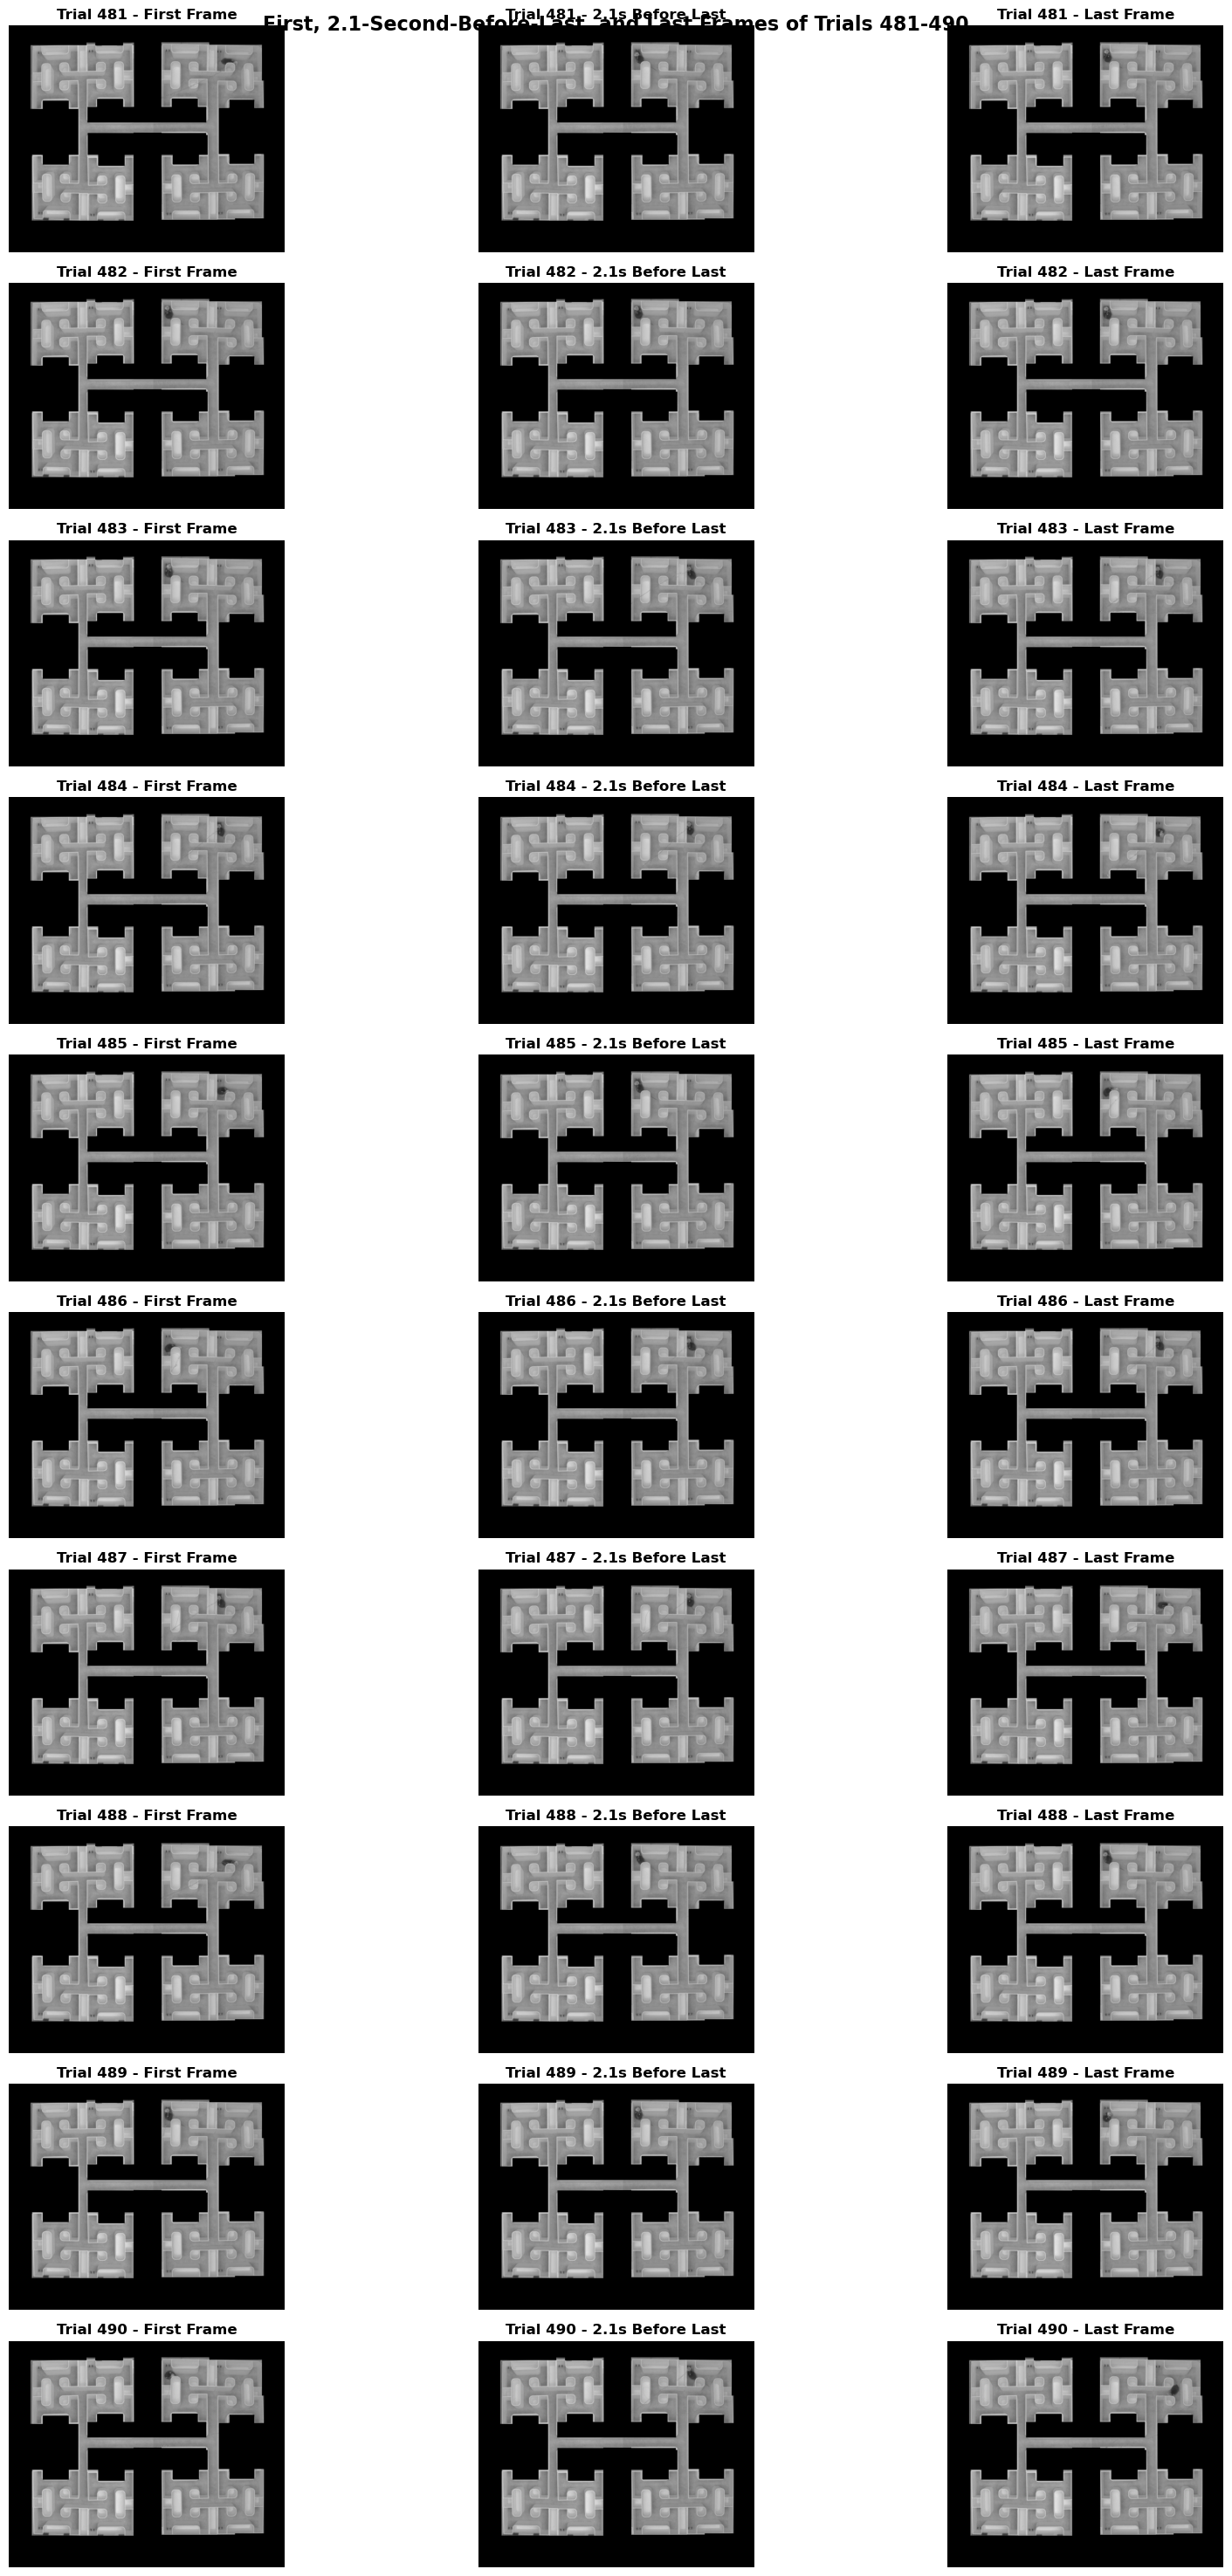


Saved frame comparison plot to: C:\Maze\Video Data\NPC2\trial_videos\trial_first_last_frames.png


In [108]:
# Plot first, 2.1-second-before-last, and last frames for each trial
total_trials = aligned_data[('trial_idx', '')].max() + 1
start_trial = total_trials - 10

fig, axes = plt.subplots(10, 3, figsize=(18, 30))
fig.suptitle(f'First, 2.1-Second-Before-Last, and Last Frames of Trials {start_trial}-{total_trials-1}', fontsize=16, fontweight='bold')

for i, trial_idx in enumerate(range(start_trial, total_trials)):
    first_frame = trial_videos[trial_idx]['first_frame']
    before_last_frame = trial_videos[trial_idx]['before_last_frame']
    last_frame = trial_videos[trial_idx]['last_frame']
    
    # Convert BGR to RGB for display
    first_frame_rgb = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)
    before_last_frame_rgb = cv2.cvtColor(before_last_frame, cv2.COLOR_BGR2RGB)
    last_frame_rgb = cv2.cvtColor(last_frame, cv2.COLOR_BGR2RGB)
    
    # Plot first frame
    axes[i, 0].imshow(first_frame_rgb)
    axes[i, 0].set_title(f'Trial {trial_idx} - First Frame', fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')
    
    # Plot frame 2.1 seconds before last
    axes[i, 1].imshow(before_last_frame_rgb)
    axes[i, 1].set_title(f'Trial {trial_idx} - 2.1s Before Last', fontsize=12, fontweight='bold')
    axes[i, 1].axis('off')
    
    # Plot last frame
    axes[i, 2].imshow(last_frame_rgb)
    axes[i, 2].set_title(f'Trial {trial_idx} - Last Frame', fontsize=12, fontweight='bold')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.savefig(output_dir / 'trial_first_last_frames.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nSaved frame comparison plot to: {output_dir / 'trial_first_last_frames.png'}")


In [ ]:
# Display trial statistics
total_trials = aligned_data[('trial_idx', '')].max() + 1
start_trial = total_trials - 10

print("="*60)
print("TRIAL VIDEO STATISTICS")
print("="*60)

for trial_idx in range(start_trial, min(start_trial + 3, total_trials)):
    trial_data = aligned_data[aligned_data[('trial_idx', '')] == trial_idx]
    print(f"\nTrial {trial_idx}:")
    print(f"  Video file: {trial_videos[trial_idx]['path'].name}")
    print(f"  Number of frames: {len(trial_data)}")
    print(f"  Duration: {trial_data[('trial_length', '')].iloc[0]:.3f} seconds")
    print(f"  Frame time range: {trial_data[('frame_time_in_trial', '')].min():.3f} - {trial_data[('frame_time_in_trial', '')].max():.3f} seconds")
    print(f"  Absolute time range: {trial_data[('frame_time_absolute', '')].min():.3f} - {trial_data[('frame_time_absolute', '')].max():.3f} seconds")

    print(f"  Has extra frame: {trial_data[('has_extra_frame', '')].iloc[0]}")print("\n" + "="*60)
    

TRIAL VIDEO STATISTICS

Trial 0:
  Video file: trial_000.mp4
  Number of frames: 542
  Duration: 13.565 seconds
  Frame time range: 0.000 - 13.525 seconds
  Absolute time range: 1571.144 - 1584.669 seconds
  Has extra frame: True

Trial 1:
  Video file: trial_001.mp4
  Number of frames: 321
  Duration: 8.039 seconds
  Frame time range: 0.000 - 8.000 seconds
  Absolute time range: 1584.830 - 1592.830 seconds
  Has extra frame: True

Trial 2:
  Video file: trial_002.mp4
  Number of frames: 1092
  Duration: 27.308 seconds
  Frame time range: 0.000 - 27.275 seconds
  Absolute time range: 1592.987 - 1620.262 seconds
  Has extra frame: True

